# Group 8 - ISIC Skin Lesion Classification with ResNet-50

**Domain option A: Medical Imaging (ISIC skin lesion classification).**

This notebook is the coding component of Part 2. It trains a ResNet-50 (ImageNet weights) to recognise
seven types of skin lesion from dermoscopy images:

| Code | Diagnosis |
|------|-----------|
| MEL | Melanoma |
| NV | Melanocytic nevus |
| BCC | Basal cell carcinoma |
| AKIEC | Actinic keratosis / intraepithelial carcinoma |
| BKL | Benign keratosis-like lesion |
| DF | Dermatofibroma |
| VASC | Vascular lesion |

**Datasets** (stored under `data/` in the project folder, or attached as Kaggle datasets):

1. **HAM10000** (ISIC 2018 Task 3, 10,015 images) - split by image into train / validation / test.
2. **ISIC 2019 training set** - extra training images (the HAM10000 images inside it are removed, and SCC is dropped because it is not one of our seven classes).
3. **BCN20000** (the labelled part of the ISIC 2019 test set) - extra training images (UNK and SCC are dropped).

Besides the image, the model also receives the patient **metadata** that comes with every dataset (age, sex and
body site of the lesion). Validation and test images come **only** from HAM10000. Because the split is by image, about a third of the
validation and test images show a lesion that also has another photo in the training set, which can make the
scores optimistic (section 2.4 prints how large this effect is).

**How to run:** open this notebook from the `code/` folder in Jupyter, select the `dev` conda environment as the kernel
(`conda activate dev`), and use *Run All*. Training at 384 px takes about 3 - 3.5 hours on an Apple M4 GPU
(kernel `dev-metal`) and much longer on a CPU. If the kernel stops,
just run all cells again: finished stages are skipped and training continues from the last saved epoch.

**How to run on Kaggle (free GPU, several hours):**

1. Kaggle -> *Create* -> *New Notebook* -> *File* -> *Import Notebook*, and upload this `.ipynb` file.
2. *Add Input* -> add these three datasets:
   `kmader/skin-cancer-mnist-ham10000` (HAM10000), `andrewmvd/isic-2019` (ISIC 2019) and
   `hillzhangjunyi/group8-bcn20000` (BCN20000, a private copy of the labelled ISIC 2019 test set).
3. *Settings*: Accelerator = **GPU T4 x2** (or P100), Internet = **on** (needed once to download the ImageNet weights).
4. *Save Version* -> *Save & Run All (Commit)*. The run continues even if the browser is closed; when it is
   finished, the saved version contains every output and the files in `/kaggle/working/outputs`.

The notebook detects Kaggle by itself (`/kaggle/input` exists) and finds each dataset by its label file, so no paths
need to be changed. The code and results are the same as in the local run; only the hardware is faster.

Each section below is labelled with the guideline item it answers (2.1 - 2.20).

## 2.1 Deep learning libraries

| Library | What we use it for |
|---------|--------------------|
| **TensorFlow 2** | Tensors, the `tf.data` input pipeline, automatic differentiation (`tf.GradientTape`) |
| **Keras 3** | Building the network (`keras.applications.ResNet50`, layers), the optimizer, training with `fit()` |
| NumPy / pandas | Arrays and tables (labels, splits, training history) |
| scikit-learn | Stratified train/validation/test split, confusion matrix, classification report |
| Matplotlib / seaborn | All plots |
| Pillow (PIL) | Reading and resizing the original JPEG images once |

In [1]:
import os
import math
import time
import zipfile
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import tensorflow as tf
import keras
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)
print("Devices:", [d.device_type for d in tf.config.list_physical_devices()])

TensorFlow: 2.18.1
Keras: 3.15.1
Devices: ['CPU', 'GPU']


### Settings

Locally, all paths are relative to the project folder, so the whole project can be moved to another computer.
On Kaggle the datasets are read from `/kaggle/input` and the outputs are written to `/kaggle/working/outputs`.
`G8_SMOKE` and `G8_OUT_DIR` are only used for a quick wiring test (a few images, one epoch per stage);
leave them unset for the real run.

Each training setup writes its model, history, figures and tables to its own folder `outputs/run_<setup>/`, so
results of earlier runs are kept and never resumed by mistake. The resized images are shared by all runs.

In [2]:
# Project folders: locally the notebook lives in code/ and the data in data/;
# on Kaggle the attached datasets are under /kaggle/input and outputs go to /kaggle/working
ON_KAGGLE = Path("/kaggle/input").is_dir()
if ON_KAGGLE:
    PROJECT_ROOT = Path("/kaggle/working")
    DATA_ROOT = Path("/kaggle/input")
else:
    PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "code" else Path.cwd()
    DATA_ROOT = PROJECT_ROOT / "data"
OUT_DIR = Path(os.environ.get("G8_OUT_DIR", PROJECT_ROOT / "outputs"))
SMOKE_TEST = os.environ.get("G8_SMOKE") == "1"

# Experiment settings
SEED = 8
IMG_SIZE = 384      # larger than ResNet's usual 224 to keep the fine details of small lesions
BATCH_SIZE = 16     # 384 px images with most of the backbone trainable need more memory per image
HEAD_EPOCHS = 1 if SMOKE_TEST else 2         # stage 1: train only the new classifier head
FINE_TUNE_EPOCHS = 1 if SMOKE_TEST else 8    # stage 2: fine-tune conv3 - conv5
HAM_EPOCHS = 1 if SMOKE_TEST else 2         # stage 3: fine-tune on the HAM10000 training images only
TOTAL_EPOCHS = HEAD_EPOCHS + FINE_TUNE_EPOCHS + HAM_EPOCHS
HEAD_LR = 1e-3
FINE_TUNE_LR = 5e-5
MIN_LR = 1e-6
HAM_LR = 1e-5

# Regularisation against overfitting
DROPOUT = 0.5            # share of the pooled features dropped during training
WEIGHT_DECAY = 0.05      # Adam weight decay: pulls every weight a little towards zero at each step
LABEL_SMOOTHING = 0.1    # targets 0.914 / 0.014 instead of 1 / 0: penalises over-confident outputs

# One fixed class order is used everywhere (label encoding, plots, reports)
CLASS_NAMES = ["MEL", "NV", "BCC", "AKIEC", "BKL", "DF", "VASC"]
NUM_CLASSES = len(CLASS_NAMES)
CLASS_TO_INDEX = {name: i for i, name in enumerate(CLASS_NAMES)}

RUN_DIR = OUT_DIR / f"run_{IMG_SIZE}px_image_split_meta"      # results of this training setup
FIG_DIR = RUN_DIR / "figures"
MODEL_DIR = RUN_DIR / "model"
FIG_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

keras.utils.set_random_seed(SEED)   # same random numbers every run (Python, NumPy, TensorFlow)


def save_figure(name):
    # Save the current figure to the run's figures folder and show it in the notebook
    plt.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")
    plt.show()


print("Running on Kaggle:", ON_KAGGLE)
print("Project root:", PROJECT_ROOT)
print("Outputs:", RUN_DIR)
print("Smoke test:", SMOKE_TEST, "| epochs:", HEAD_EPOCHS, "+", FINE_TUNE_EPOCHS, "+", HAM_EPOCHS)

Running on Kaggle: False
Project root: /Users/hill/dev/DL Group Assignment
Outputs: /Users/hill/dev/DL Group Assignment/outputs/run_384px_image_split_meta
Smoke test: False | epochs: 2 + 8 + 2


## 2.2 How TensorFlow tracks the forward pass for automatic differentiation

TensorFlow uses **`tf.GradientTape`**. While code runs inside a `with tf.GradientTape()` block, every operation on
trainable variables (multiply, add, convolution, ReLU, ...) is written onto the "tape" together with the values it
produced. This is the **forward pass**. Calling `tape.gradient(loss, variables)` then reads the tape **backwards**
and applies the chain rule to each recorded operation, giving the derivative of the loss with respect to every
variable. This is the **backward pass** (reverse-mode automatic differentiation).

It plays the same role as PyTorch's `requires_grad=True` + `loss.backward()`: in PyTorch each tensor remembers how
it was created; in TensorFlow the tape remembers it. Keras' `model.fit()` uses a `GradientTape` internally for
every training batch, so we do not write the loop ourselves. The small example below shows the idea on one number.

In [3]:
w = tf.Variable(3.0)   # a trainable parameter
x = tf.constant(2.0)   # an input

with tf.GradientTape() as tape:
    y = w * x ** 2 + 1          # forward pass, recorded on the tape: y = 3 * 4 + 1 = 13

dy_dw = tape.gradient(y, w)     # backward pass: dy/dw = x^2 = 4
print("y =", y.numpy())
print("dy/dw =", dy_dw.numpy())

2026-10-30 18:12:49.745239: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M4
2026-10-30 18:12:49.745269: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2026-10-30 18:12:49.745274: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.92 GB
I0000 00:00:1793355169.745496 8722163 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
I0000 00:00:1793355169.745521 8722163 pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


y = 13.0
dy/dw = 4.0


## 2.3 Training mode vs evaluation mode (memory)

* **Training mode** - inside a `GradientTape` the framework must **keep every intermediate activation** of the
  forward pass, because the backward pass needs them to compute gradients. For ResNet-50 that is the output of
  every convolution for every image in the batch, plus the gradients themselves and Adam's two moment vectors for
  every trainable weight. Layers also behave differently: `Dropout` randomly switches units off.
* **Evaluation mode** - `model.predict()` / `model(x, training=False)` runs **without a tape**. Each activation can
  be thrown away as soon as the next layer has used it, and no gradients or optimizer states are created. This is
  TensorFlow's equivalent of PyTorch's `model.eval()` + `torch.no_grad()`, and it uses far less memory, so
  larger batches fit. `Dropout` is switched off and BatchNorm uses its stored running statistics.

The example below shows the behavioural difference with a `Dropout` layer.

In [4]:
dropout = keras.layers.Dropout(0.5, seed=SEED)
ones = tf.ones((1, 8))
print("training=True :", dropout(ones, training=True).numpy())    # about half the units are 0, the rest scaled x2
print("training=False:", dropout(ones, training=False).numpy())   # unchanged

training=True : [[2. 2. 0. 0. 0. 0. 0. 2.]]
training=False: [[1. 1. 1. 1. 1. 1. 1. 1.]]


## 2.4 Data loading, label encoding and preprocessing

**Loading.** We read the label table of each dataset and find every image file under `data/` (sub-folders are
searched too).

**Label encoding.** Every diagnosis is mapped to the same seven class names (ISIC 2019 calls AKIEC `AK`), then to an
integer index `0 - 6` in the order of `CLASS_NAMES`, and finally to a **one-hot vector** (e.g. NV = `[0,1,0,0,0,0,0]`),
which is what categorical cross-entropy expects.

**Metadata encoding.** Each dataset also lists the patient's age, sex and the body site of the lesion. Age, sex and
body site are known risk factors (for example, melanoma is more common in older patients and on the back, while
nevi are typical for younger patients), so they help with the classes that look alike. The three datasets name body
sites differently (`back`, `posterior torso`, ...), so the sites are mapped to six common groups. Every image
gets a vector of 10 numbers: age / 100, a flag for unknown age, one-hot sex (male, female) and one-hot body-site
group. Unknown values are encoded as zeros.

**Splitting.** We split the HAM10000 images at random (70 % / 15 % / 15 %, stratified by class), as many public
HAM10000 projects do. HAM10000 contains 10,015 images of only 7,470 lesions, so some lesions have several photos.
With an image-level split, about a third of the validation and test images show a lesion that also has a
different photo in the training set. This is a form of **data leakage** that can make the validation and test
scores optimistic, so the cell below prints how large it is and section 2.14 checks its effect.
For comparison, an earlier run with a **lesion-level split** (all photos of a lesion in the same split) and the same
model reached **86.1 % validation and 86.0 % test accuracy**; that is the better estimate for completely new
patients. Section 2.14 also reports the test accuracy on new lesions only. ISIC 2019 and BCN20000 are only added
to the **training** set.

In [5]:
def find_images(folder):
    # Map image id (file name without .jpg) -> path, searching all sub-folders
    return {p.stem: p for p in Path(folder).rglob("*.jpg")}


def dataset_folder(local_name, label_file):
    # Locally: data/<local_name>. On Kaggle: the attached dataset that contains the label file.
    if not ON_KAGGLE:
        return DATA_ROOT / local_name
    found = list(DATA_ROOT.rglob(label_file))
    assert found, f"Add the Kaggle dataset that contains {label_file} (Add Input)"
    return found[0].parent


HAM_DIR = dataset_folder("ISIC 2018", "HAM10000_metadata.csv")
ISIC19_DIR = dataset_folder("ISIC 2019", "ISIC_2019_Training_GroundTruth.csv")
bcn_dir = dataset_folder("BCN20000", "ISIC_2019_Test_GroundTruth.csv")
print("Dataset folders:", HAM_DIR, ISIC19_DIR, bcn_dir, sep="\n  ")

# Body sites are named differently in the three datasets; map them to six common groups
SITE_GROUPS = {
    "torso": ["anterior torso", "posterior torso", "lateral torso", "back", "trunk", "abdomen", "chest"],
    "head/neck": ["head/neck", "face", "neck", "scalp", "ear"],
    "upper extremity": ["upper extremity", "hand"],
    "lower extremity": ["lower extremity", "foot"],
    "palms/soles": ["palms/soles", "acral"],
    "oral/genital": ["oral/genital", "genital"],
}
SITE_TO_GROUP = {site: group for group, sites in SITE_GROUPS.items() for site in sites}


def add_isic_metadata(table, folder, file_name):
    # Age, sex and body site from an ISIC metadata file; if the file is missing, they stay unknown
    found = list(Path(folder).rglob(file_name))
    if not found:
        print(f"{file_name} not found - age, sex and body site are treated as unknown")
        table[["age", "sex", "site"]] = np.nan
        return
    meta = pd.read_csv(found[0]).set_index("image")
    table["age"] = table["image"].map(meta["age_approx"])
    table["sex"] = table["image"].map(meta["sex"])
    table["site"] = table["image"].map(meta["anatom_site_general"]).map(SITE_TO_GROUP)


# 1) HAM10000 (ISIC 2018 Task 3): train / validation / test
ham_meta = pd.read_csv(next(HAM_DIR.rglob("HAM10000_metadata.csv")))
ham_paths = find_images(HAM_DIR)
ham = pd.DataFrame({
    "image": ham_meta["image_id"],
    "lesion_id": ham_meta["lesion_id"],
    "label": ham_meta["dx"].str.upper(),        # nv -> NV, akiec -> AKIEC, ...
    "source": "HAM10000",
    "age": ham_meta["age"],
    "sex": ham_meta["sex"],
    "site": ham_meta["localization"].map(SITE_TO_GROUP),   # "unknown" -> NaN
})
ham["path"] = ham["image"].map(ham_paths)

# 2) ISIC 2019 training set: extra training images
LABEL_COLUMNS_2019 = ["MEL", "NV", "BCC", "AK", "BKL", "DF", "VASC", "SCC", "UNK"]
isic19_table = pd.read_csv(next(ISIC19_DIR.rglob("ISIC_2019_Training_GroundTruth.csv")))
isic19 = pd.DataFrame({
    "image": isic19_table["image"],
    "label": isic19_table[LABEL_COLUMNS_2019].idxmax(axis=1).replace({"AK": "AKIEC"}),
    "source": "ISIC 2019",
})
isic19["path"] = isic19["image"].map(find_images(ISIC19_DIR))
add_isic_metadata(isic19, ISIC19_DIR, "ISIC_2019_Training_Metadata.csv")
in_ham = isic19["image"].isin(ham["image"])
print("ISIC 2019 images that are already in HAM10000 (removed):", in_ham.sum())
isic19 = isic19[~in_ham]

# 3) BCN20000 (labelled ISIC 2019 test set): extra training images
bcn_paths = find_images(bcn_dir)
if not bcn_paths and (bcn_dir / "ISIC_2019_Test_Input.zip").exists():
    with zipfile.ZipFile(bcn_dir / "ISIC_2019_Test_Input.zip") as archive:   # unzip once if needed
        archive.extractall(bcn_dir)
    bcn_paths = find_images(bcn_dir)
bcn_table = pd.read_csv(bcn_dir / "ISIC_2019_Test_GroundTruth.csv")
bcn = pd.DataFrame({
    "image": bcn_table["image"],
    "label": bcn_table[LABEL_COLUMNS_2019].idxmax(axis=1).replace({"AK": "AKIEC"}),
    "source": "BCN20000",
})
bcn["path"] = bcn["image"].map(bcn_paths)
add_isic_metadata(bcn, bcn_dir, "ISIC_2019_Test_Metadata.csv")

# Keep only our seven classes (drops SCC and UNK) and check that every image file exists
isic19 = isic19[isic19["label"].isin(CLASS_NAMES)]
bcn = bcn[bcn["label"].isin(CLASS_NAMES)]
for name, table in [("HAM10000", ham), ("ISIC 2019", isic19), ("BCN20000", bcn)]:
    assert table["path"].notna().all(), f"{name}: some image files are missing"
    print(f"{name}: {len(table):,} images")

Dataset folders:
  /Users/hill/dev/DL Group Assignment/data/ISIC 2018
  /Users/hill/dev/DL Group Assignment/data/ISIC 2019
  /Users/hill/dev/DL Group Assignment/data/BCN20000
ISIC 2019 images that are already in HAM10000 (removed): 10015
HAM10000: 10,015 images
ISIC 2019: 14,885 images
BCN20000: 6,026 images


validation: 36.7% of the images show a lesion that also has a photo in the training set
test: 34.1% of the images show a lesion that also has a photo in the training set

       train  validation  test
label                         
MEL     5515         167   167
NV     13358        1006  1006
BCC     4144          77    77
AKIEC   1340          49    49
BKL     2954         165   165
DF       296          17    17
VASC     314          21    22
Total  27921        1502  1503

Training images by source:
source
ISIC 2019    14885
HAM10000      7010
BCN20000      6026
Name: count, dtype: int64


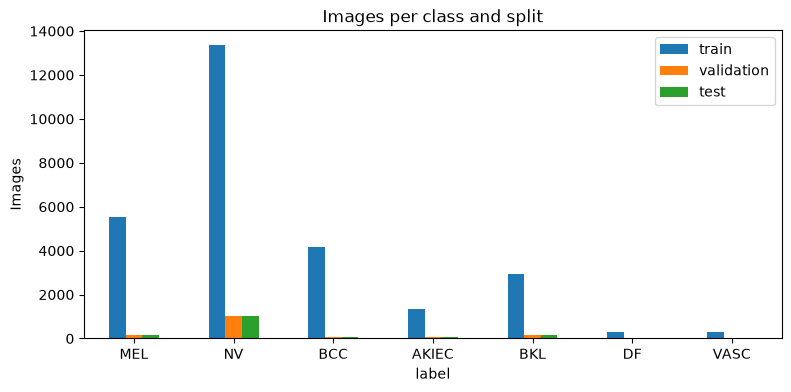

In [6]:
# Image-level split of HAM10000 (stratified by class). Photos of the same lesion can end up in different
# splits, so the validation and test scores are optimistic (data leakage, see the text above).
ham_train, other = train_test_split(ham, test_size=0.30, stratify=ham["label"], random_state=SEED)
val_df, test_df = train_test_split(other, test_size=0.50, stratify=other["label"], random_state=SEED)
val_df, test_df = val_df.reset_index(drop=True), test_df.reset_index(drop=True)
train_df = pd.concat([ham_train, isic19, bcn], ignore_index=True)

if SMOKE_TEST:   # wiring test only: 8 images per class in each split
    train_df, val_df, test_df = [d.groupby("label").head(8).reset_index(drop=True)
                                 for d in (train_df, val_df, test_df)]

# Safety check: no image is used in two splits
all_images = pd.concat([train_df, val_df, test_df])["image"]
assert all_images.is_unique

# Size of the leakage: images whose lesion also has a photo in the training set
for name, d in [("validation", val_df), ("test", test_df)]:
    shared = d["lesion_id"].isin(ham_train["lesion_id"]).mean()
    print(f"{name}: {shared:.1%} of the images show a lesion that also has a photo in the training set")
print()

# Label encoding: class name -> integer index (one-hot is done in the tf.data pipeline)
for d in (train_df, val_df, test_df):
    d["y"] = d["label"].map(CLASS_TO_INDEX)

counts = pd.DataFrame({
    "train": train_df["label"].value_counts(),
    "validation": val_df["label"].value_counts(),
    "test": test_df["label"].value_counts(),
}).reindex(CLASS_NAMES)
counts.loc["Total"] = counts.sum()
print(counts)
print("\nTraining images by source:")
print(train_df["source"].value_counts())

counts.drop("Total").plot.bar(figsize=(9, 4), rot=0, title="Images per class and split")
plt.ylabel("Images")
save_figure("class_distribution.png")

### Preprocessing

1. **Resize once.** The original images are up to 1024 px wide. Decoding them again in every epoch would waste a lot
   of CPU time, so each image is resized to 384 x 384 **one time** and saved under `outputs/resized_384/`. Later
   runs reuse these files. ResNet-50 was pre-trained at 224 x 224, but a convolutional network works at any input
   size; 384 x 384 keeps more of the fine structures (dots, streaks, pigment network) that separate the classes.
2. **Input pipeline (`tf.data`).** For every batch: read the small JPEG, convert it to `float32`, add the metadata
   vector of the image and turn the class index into a one-hot vector. The training set is shuffled every epoch.
3. **ResNet-50 preprocessing** (RGB -> BGR and subtracting the ImageNet channel means) happens *inside* the model,
   so the same model can be given raw images at prediction time.

In [7]:
RESIZED_DIR = OUT_DIR / f"resized_{IMG_SIZE}"
RESIZED_DIR.mkdir(parents=True, exist_ok=True)


def resized_path(original_path):
    return RESIZED_DIR / (Path(original_path).stem + ".jpg")


def resize_once(original_path):
    target = resized_path(original_path)
    if not target.exists():
        image = Image.open(original_path).convert("RGB").resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
        temporary = target.with_name(target.stem + ".tmp")
        image.save(temporary, format="JPEG", quality=95)
        temporary.replace(target)   # rename at the end, so a stopped run never leaves half a file


all_paths = pd.concat([train_df, val_df, test_df])["path"]
todo = [p for p in all_paths if not resized_path(p).exists()]
print(f"Resizing {len(todo):,} of {len(all_paths):,} images (already done: {len(all_paths) - len(todo):,})")
start = time.time()
with ThreadPoolExecutor(max_workers=8) as pool:
    list(pool.map(resize_once, todo))
print(f"Done in {time.time() - start:.0f} s")

for d in (train_df, val_df, test_df):
    d["file"] = d["path"].map(lambda p: str(resized_path(p)))

Resizing 0 of 30,926 images (already done: 30,926)
Done in 0 s


In [8]:
def load_image(file, label_index):
    image = tf.io.decode_jpeg(tf.io.read_file(file), channels=3)
    image = tf.ensure_shape(image, (IMG_SIZE, IMG_SIZE, 3))
    image = tf.cast(image, tf.float32)                  # pixel values stay in 0 - 255
    return image, tf.one_hot(label_index, NUM_CLASSES)  # label encoding: index -> one-hot


def metadata_matrix(df):
    # One row per image: [age / 100, age unknown, male, female, one column per body-site group]
    age = df["age"].to_numpy(dtype="float32")
    columns = [np.nan_to_num(age / 100), np.isnan(age), df["sex"] == "male", df["sex"] == "female"]
    columns += [df["site"] == group for group in SITE_GROUPS]
    return np.stack([np.asarray(c, dtype="float32") for c in columns], axis=1)


NUM_METADATA = metadata_matrix(train_df).shape[1]


def load_example(file, metadata, label_index):
    image, label = load_image(file, label_index)
    return {"image": image, "metadata": metadata}, label   # the model has two inputs


def make_dataset(df, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((df["file"].values, metadata_matrix(df), df["y"].values))
    if shuffle:
        ds = ds.shuffle(len(df), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(load_example, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


train_ds = make_dataset(train_df, shuffle=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

### Data augmentation

Augmentation layers are only active while training (`training=True`); for validation, test and prediction they
pass the image through unchanged.

* random horizontal and vertical flips,
* random rotation up to +/- 90 degrees (empty corners are filled by reflecting the image),
* random zoom in or out up to 20 %,
* random shift up to 10 % of the width and height,
* random brightness and contrast changes up to 20 % ("colour jitter").

Our earlier runs used 15 % zoom, no shift and 10 % colour jitter and were overfitting (training accuracy kept
rising while validation accuracy stopped improving), so this run uses stronger augmentation.

A skin lesion has no natural "up" direction and photos are taken with different cameras and lighting, so all of
these changes produce realistic new images of the same lesion.

In [9]:
random_rotation = keras.layers.RandomRotation(0.25, fill_mode="reflect", seed=SEED, name="random_rotation")
colour_jitter = keras.Sequential([
    keras.layers.RandomBrightness(0.2, value_range=(0, 255), seed=SEED),
    keras.layers.RandomContrast(0.2, value_range=(0, 255), seed=SEED),
], name="colour_jitter")

augmentation = keras.Sequential([
    keras.layers.RandomFlip("horizontal_and_vertical", seed=SEED),
    random_rotation,
    keras.layers.RandomZoom(0.2, fill_mode="reflect", seed=SEED),
    keras.layers.RandomTranslation(0.1, 0.1, fill_mode="reflect", seed=SEED),
    colour_jitter,
], name="augmentation")

## 2.5 A batch through the pipeline, and one sample with two random augmentations

Image batch: (16, 384, 384, 3) <dtype: 'float32'> | pixel range: 0.0 - 255.0
Metadata batch: (16, 10) | first row: [0.65 0.   1.   0.   0.   0.   1.   0.   0.   0.  ]
Label batch: (16, 7) <dtype: 'float32'>
First label (one-hot): [0. 0. 0. 0. 1. 0. 0.] -> BKL


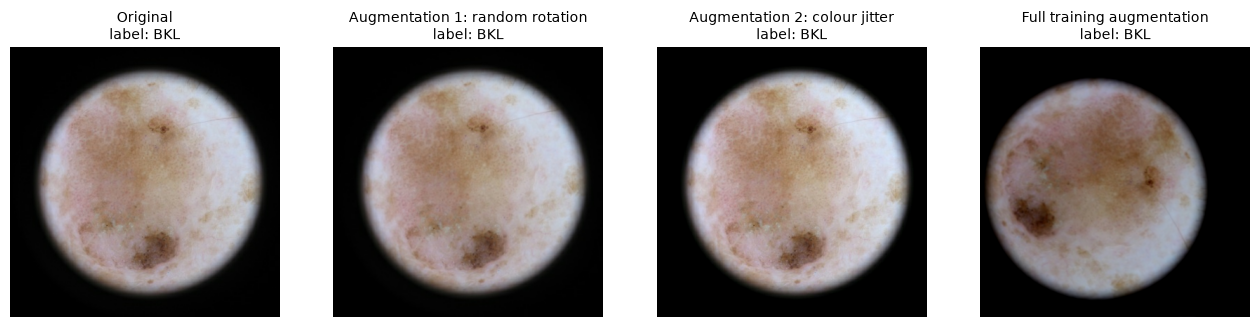

In [10]:
inputs, labels = next(iter(train_ds))
images = inputs["image"]
print("Image batch:", images.shape, images.dtype, "| pixel range:",
      float(tf.reduce_min(images)), "-", float(tf.reduce_max(images)))
print("Metadata batch:", inputs["metadata"].shape, "| first row:", inputs["metadata"][0].numpy())
print("Label batch:", labels.shape, labels.dtype)
print("First label (one-hot):", labels[0].numpy(), "->", CLASS_NAMES[int(np.argmax(labels[0]))])

sample = images[:1]
label_name = CLASS_NAMES[int(np.argmax(labels[0]))]
views = [
    ("Original", sample),
    ("Augmentation 1: random rotation", random_rotation(sample, training=True)),
    ("Augmentation 2: colour jitter", colour_jitter(sample, training=True)),
    ("Full training augmentation", augmentation(sample, training=True)),
]
fig, axes = plt.subplots(1, len(views), figsize=(16, 4.5))
for ax, (title, view) in zip(axes, views):
    ax.imshow(np.clip(view[0].numpy(), 0, 255).astype("uint8"))
    ax.set_title(f"{title}\nlabel: {label_name}", fontsize=10)
    ax.axis("off")
save_figure("augmentation_examples.png")

## 2.6 How augmentation adds variance without changing the label

Every epoch the network sees a slightly different version of each training image: rotated, flipped, zoomed,
shifted, a little brighter or with more contrast. The **diagnosis does not depend on these properties** - a melanoma rotated by
40 degrees or photographed under brighter light is still a melanoma - so the one-hot label stays the same while the
pixel values change. This enlarges the effective training set and increases its variance, which forces the network
to learn features that are stable under these changes (colour patterns, borders, structures inside the lesion)
instead of memorising the exact pixels of each photo. The result is less overfitting and better accuracy on new
images. We deliberately avoid transformations that *could* change the diagnosis, such as strong colour shifts
(colour is an important clinical cue) or crops that could cut the lesion out of the image.

## 2.7 Building the model (ResNet-50 with transfer learning)

* **Backbone:** `keras.applications.ResNet50` with **ImageNet** weights and without its 1000-class top layer.
  It turns a 384 x 384 x 3 image into a 12 x 12 x 2048 block of features.
* **Head:** global average pooling (2048 numbers per image) -> dropout 0.5 -> joined with the **10 metadata
  numbers** (age, sex, body site) -> a dense layer with **7 outputs (logits)** -> **softmax** to get probabilities.
  The model therefore has two inputs, `image` and `metadata`.
* The backbone is called with `training=False`, so its BatchNorm layers always use their ImageNet statistics, also
  later when we fine-tune it. This keeps fine-tuning stable with small batches.
* At first the backbone is **frozen** (`trainable = False`): only the head (about 14 thousand weights) is trained.

In [11]:
base_model = keras.applications.ResNet50(include_top=False, weights="imagenet",
                                         input_shape=(IMG_SIZE, IMG_SIZE, 3))
base_model.trainable = False

image_input = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="image")
metadata_input = keras.Input(shape=(NUM_METADATA,), name="metadata")
x = augmentation(image_input)                              # only active during training
x = keras.layers.Lambda(keras.applications.resnet50.preprocess_input,   # RGB -> BGR, subtract ImageNet means
                        name="resnet50_preprocessing")(x)
x = base_model(x, training=False)                          # BatchNorm stays in inference mode
x = keras.layers.GlobalAveragePooling2D(name="global_avg_pool")(x)
x = keras.layers.Dropout(DROPOUT, name="dropout")(x)
x = keras.layers.Concatenate(name="image_and_metadata")([x, metadata_input])   # 2048 + 10 numbers
logits = keras.layers.Dense(NUM_CLASSES, name="logits")(x)
outputs = keras.layers.Softmax(name="probabilities")(logits)
model = keras.Model({"image": image_input, "metadata": metadata_input}, outputs, name="resnet50_skin_lesion")

model.summary()

Model: "resnet50_skin_lesion"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image (InputLayer)  │ (None, 384, 384,  │          0 │ -                 │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ augmentation        │ (None, 384, 384,  │          0 │ image[0][0]       │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resnet50_preproces… │ (None, 384, 384,  │          0 │ augmentation[0][… │
│ (Lambda)            │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resnet50            │ (None, 12, 12,    │ 23,587,712 │ resnet50_preproc… │
│ (Functional)        │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_avg_pool     │ (None, 2048)      │          0 │ resnet50[0][0]    │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 2048)      │          0 │ global_avg_pool[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ metadata            │ (None, 10)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ image_and_metadata  │ (None, 2058)      │          0 │ dropout[0][0],    │
│ (Concatenate)       │                   │            │ metadata[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ logits (Dense)      │ (None, 7)         │     14,413 │ image_and_metada… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ probabilities       │ (None, 7)         │          0 │ logits[0][0]      │
│ (Softmax)           │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 23,602,125 (90.03 MB)

 Trainable params: 14,413 (56.30 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

The summary shows ResNet-50 as one nested layer. The table below lists the output shape at the end of each ResNet
stage, which is useful for question 2.9.

In [12]:
stage_layers = ["conv1_relu", "conv2_block3_out", "conv3_block4_out", "conv4_block6_out", "conv5_block3_out"]
rows = []
for name in stage_layers:
    _, h, w, c = base_model.get_layer(name).output.shape
    rows.append({"layer": name, "height": h, "width": w, "channels": c})
print(pd.DataFrame(rows).to_string(index=False))

           layer  height  width  channels
      conv1_relu     192    192        64
conv2_block3_out      96     96       256
conv3_block4_out      48     48       512
conv4_block6_out      24     24      1024
conv5_block3_out      12     12      2048


## 2.8 Feature maps from a hidden layer

We pass one test image through the backbone and show 16 of the 256 channels produced by `conv2_block3_out` (the end of
the first residual stage, 96 x 96). Bright areas are where that filter responds strongly. Early layers react to
simple patterns such as edges, colour blobs and the lesion border.

Feature map shape: (96, 96, 256)


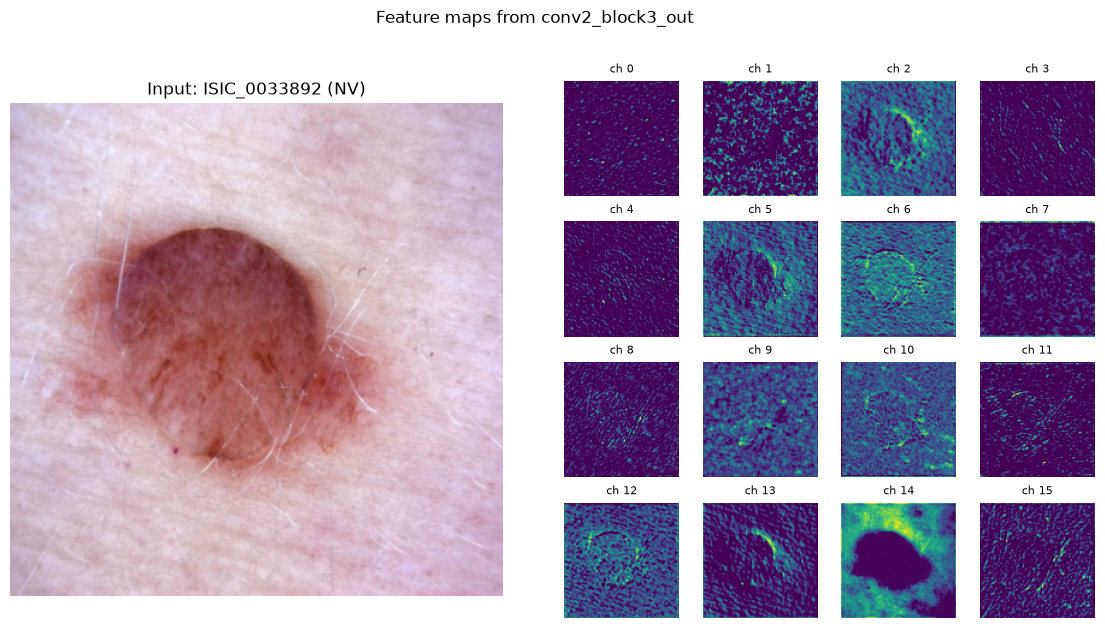

In [13]:
feature_extractor = keras.Model(base_model.input, base_model.get_layer("conv2_block3_out").output)
example = test_df.iloc[0]
example_image, _ = load_image(example["file"], example["y"])
feature_maps = feature_extractor(
    keras.applications.resnet50.preprocess_input(example_image[None]), training=False).numpy()[0]
print("Feature map shape:", feature_maps.shape)

fig = plt.figure(figsize=(14, 7))
ax = fig.add_subplot(1, 2, 1)
ax.imshow(example_image.numpy().astype("uint8"))
ax.set_title(f"Input: {example['image']} ({example['label']})")
ax.axis("off")
for i in range(16):
    ax = fig.add_subplot(4, 8, 4 + (i // 4) * 8 + (i % 4) + 1)
    ax.imshow(feature_maps[:, :, i], cmap="viridis")
    ax.set_title(f"ch {i}", fontsize=8)
    ax.axis("off")
fig.suptitle("Feature maps from conv2_block3_out")
save_figure("feature_maps.png")

## 2.9 Why height/width shrink while channels grow, and how backpropagation updates the weights

**Shrinking spatial size, growing depth.** ResNet-50 starts with a stride-2 convolution and a max-pool (384 -> 96),
and then each new stage begins with a stride-2 convolution, halving height and width again (96 -> 48 -> 24 -> 12).
At the same time the number of filters doubles (256 -> 512 -> 1024 -> 2048 channels after each bottleneck stage),
as the table above shows. Each position in a deeper map "sees" a larger part of the image (a larger receptive field)
and combines the simpler features of earlier layers into more complex ones (edge -> texture -> pigment network ->
whole-lesion pattern). We need fewer positions, because the information is more abstract, but many more channels,
because there are many more kinds of complex patterns than simple edges. Halving H and W while doubling the channels
also keeps the amount of computation per stage roughly constant.

**Backpropagation.** Each trainable parameter (convolution kernels, dense weights and biases) is updated as
follows: (1) the forward pass computes the predictions and the cross-entropy loss; (2) the backward pass uses the
chain rule to compute the gradient of the loss with respect to every trainable weight, starting from the output
layer and moving back towards the input; (3) the optimizer (Adam) moves every weight a small step in the direction
that lowers the loss. Frozen layers (`trainable=False`) still pass the gradient through during the backward pass but
their own weights are not changed. The model summary shows how many parameters are trainable in each stage.

## 2.10 Training with Adam

Training has two stages (a common transfer-learning recipe):

| Stage | Epochs | What is trained | Optimizer and learning rate |
|-------|--------|-----------------|-----------------------------|
| 1 | 2 | only the new head (backbone frozen) | Adam, 1e-3, weight decay 0.05 |
| 2 | 8 | head + the ResNet stages `conv3` - `conv5` (BatchNorm stays frozen) | Adam, 5e-5 decreasing to 1e-6 (cosine), weight decay 0.05 |
| 3 | 2 | same as stage 2, but only on the **HAM10000** training images | Adam, 1e-5 (constant), weight decay 0.05 |

Stage 1 first teaches the randomly initialised head to use the ImageNet features; otherwise its large random
gradients would damage the pre-trained weights. Stage 2 then adapts the filters of `conv3` - `conv5` to skin lesions
with a small learning rate. The first two stages (`conv1`, `conv2`) only detect general edges and colours and stay
frozen: this saves about a quarter of the time per epoch, and together with fewer epochs (2 + 8 instead of
3 + 12 in our earlier runs) the whole training takes about 3 hours instead of 6 - 7 hours on an Apple M4 GPU.

**Stage 3 (HAM10000 only).** About three quarters of the training images come from ISIC 2019 and BCN20000, which
were taken with other cameras in other hospitals, while the validation and test images all come from HAM10000.
Stage 3 starts from the best weights so far and trains two more epochs on the HAM10000 training images only, with
a small learning rate, so the model adapts to the colours and image style of HAM10000 without forgetting what it
learned from the larger data. Because the best epoch is chosen by validation accuracy, stage 3 is only kept if
it actually helps.

**Why this setup.** Our first run used 224 x 224 images and fine-tuned only `conv4` and `conv5`. It reached 85.3 %
validation accuracy, was clearly overfitting after epoch 9 and mostly confused melanoma with nevi. Test-time
augmentation and adjusting the class thresholds of that model gained less than one point. This run therefore
changes the model itself: a higher input resolution (384 x 384) and fine-tuning of the whole backbone. With the
lesion-level split this reached 86.1 % validation and 86.0 % test accuracy. A second run with the image-level split
(section 2.4) reached 85.8 % validation and 87.6 % test accuracy, and its training accuracy (91 %) was again clearly
above the validation accuracy.

**Regularisation against overfitting.** The run after that therefore kept the model and the split but added four
kinds of regularisation:

* **stronger augmentation** (section 2.4): every epoch shows more varied versions of each image;
* **dropout 0.5** instead of 0.3 before the output layer, so the head cannot rely on a few features;
* **weight decay 0.05** (a weight penalty similar to L2 regularisation): Adam shrinks every weight by
  `learning rate x 0.05 x weight` at each step, which keeps the fine-tuned filters close to small values unless the
  data really needs them;
* **label smoothing 0.1**: the target for the true class is 0.914 instead of 1, which penalises extremely
  confident outputs. Because of this the reported loss is slightly higher than plain cross-entropy.

This removed the overfitting (training 85.6 % vs validation 85.1 %), but validation accuracy did not improve, so
the current run keeps these settings and gives the model more information instead: the patient metadata
(section 2.4) and stage 3 below.

The model with the **highest validation accuracy** is saved to
`outputs/run_384px_image_split_meta/model/best.weights.h5`. The test set is not used until training is finished.
Every epoch is logged to `outputs/run_384px_image_split_meta/training_history.csv`, and
`BackupAndRestore`
saves a backup after each epoch: if the kernel stops, run all cells again and training continues where it stopped.

In [14]:
HEAD_WEIGHTS = MODEL_DIR / "head.weights.h5"
BEST_WEIGHTS = MODEL_DIR / "best.weights.h5"
HISTORY_CSV = RUN_DIR / "training_history.csv"
loss_fn = keras.losses.CategoricalCrossentropy(label_smoothing=LABEL_SMOOTHING)


def learning_rate_for(epoch, current_lr=None):
    # Stage 1: constant 1e-3. Stage 2: cosine decay from 1e-4 to 1e-6.
    if epoch < HEAD_EPOCHS:
        return HEAD_LR
    if epoch >= HEAD_EPOCHS + FINE_TUNE_EPOCHS:   # stage 3: constant small learning rate
        return HAM_LR
    progress = (epoch - HEAD_EPOCHS) / max(FINE_TUNE_EPOCHS - 1, 1)
    return MIN_LR + 0.5 * (FINE_TUNE_LR - MIN_LR) * (1 + math.cos(math.pi * progress))


def read_history():
    if not HISTORY_CSV.exists() or HISTORY_CSV.stat().st_size == 0:   # empty: stopped before epoch 1 ended
        return pd.DataFrame(columns=["epoch", "accuracy", "loss", "val_accuracy", "val_loss", "learning_rate"])
    return pd.read_csv(HISTORY_CSV).drop_duplicates("epoch", keep="last").sort_values("epoch")


def training_callbacks(backup_name):
    history = read_history()
    best_so_far = history["val_accuracy"].max() if len(history) else None
    return [
        keras.callbacks.LearningRateScheduler(learning_rate_for),
        keras.callbacks.ModelCheckpoint(BEST_WEIGHTS, monitor="val_accuracy", mode="max", save_best_only=True,
                                        save_weights_only=True, initial_value_threshold=best_so_far),
        keras.callbacks.CSVLogger(HISTORY_CSV, append=True),
        keras.callbacks.BackupAndRestore(MODEL_DIR / backup_name),
        keras.callbacks.LambdaCallback(on_epoch_begin=lambda epoch, logs: print(
            f"{time.strftime('%H:%M:%S')}  epoch {epoch + 1}/{TOTAL_EPOCHS} started", flush=True)),
    ]


print(f"Training images: {len(train_df):,} | steps per epoch: {math.ceil(len(train_df) / BATCH_SIZE)}")
print("Trainable weights in stage 1:", sum(int(np.prod(w.shape)) for w in model.trainable_weights))

Training images: 27,921 | steps per epoch: 1746
Trainable weights in stage 1: 14413


In [15]:
# ---------- Stage 1: train the classifier head only ----------
if HEAD_WEIGHTS.exists():
    model.load_weights(HEAD_WEIGHTS)
    print("Stage 1 already finished - loaded", HEAD_WEIGHTS.name)
else:
    model.compile(optimizer=keras.optimizers.Adam(HEAD_LR, weight_decay=WEIGHT_DECAY), loss=loss_fn, metrics=["accuracy"])
    model.fit(train_ds, validation_data=val_ds, epochs=HEAD_EPOCHS,
              callbacks=training_callbacks("backup_stage1"), verbose=2)
    model.save_weights(HEAD_WEIGHTS)

18:12:52  epoch 1/12 started
Epoch 1/2


/opt/homebrew/Caskroom/miniconda/base/envs/dev-metal/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
2026-10-30 18:12:53.132709: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


1746/1746 - 567s - 325ms/step - accuracy: 0.5887 - loss: 1.3609 - val_accuracy: 0.7224 - val_loss: 1.0636 - learning_rate: 0.0010
18:22:19  epoch 2/12 started
Epoch 2/2
1746/1746 - 563s - 323ms/step - accuracy: 0.6272 - loss: 1.2597 - val_accuracy: 0.7430 - val_loss: 1.0076 - learning_rate: 0.0010


In [16]:
# ---------- Stage 2: fine-tune conv3 - conv5 (conv1, conv2 and all BatchNorm layers stay frozen) ----------
base_model.trainable = True
for layer in base_model.layers:
    layer.trainable = (layer.name.startswith(("conv3", "conv4", "conv5"))
                       and not isinstance(layer, keras.layers.BatchNormalization))
print("Trainable weights in stage 2:", sum(int(np.prod(w.shape)) for w in model.trainable_weights))

model.compile(optimizer=keras.optimizers.Adam(FINE_TUNE_LR, weight_decay=WEIGHT_DECAY), loss=loss_fn, metrics=["accuracy"])

finished_epochs = len(read_history())
if finished_epochs >= HEAD_EPOCHS + FINE_TUNE_EPOCHS:
    print("Stage 2 already finished -", finished_epochs, "epochs in", HISTORY_CSV.name)
else:
    model.fit(train_ds, validation_data=val_ds, initial_epoch=HEAD_EPOCHS, epochs=HEAD_EPOCHS + FINE_TUNE_EPOCHS,
              callbacks=training_callbacks("backup_stage2"), verbose=2)

# ---------- Stage 3: fine-tune on the HAM10000 training images only (same trainable layers) ----------
if len(read_history()) >= TOTAL_EPOCHS:
    print("Stage 3 already finished")
else:
    model.load_weights(BEST_WEIGHTS)   # start from the best weights so far
    ham_train_ds = make_dataset(train_df[train_df["source"] == "HAM10000"], shuffle=True)
    model.fit(ham_train_ds, validation_data=val_ds, initial_epoch=HEAD_EPOCHS + FINE_TUNE_EPOCHS,
              epochs=TOTAL_EPOCHS, callbacks=training_callbacks("backup_stage3"), verbose=2)

history = read_history()
history["epoch"] = history["epoch"] + 1    # CSVLogger counts from 0; show epochs from 1
print(history.round(4).to_string(index=False))

Trainable weights in stage 2: 23272013
18:31:43  epoch 3/12 started
Epoch 3/10
1746/1746 - 1192s - 683ms/step - accuracy: 0.6743 - loss: 1.1331 - val_accuracy: 0.7597 - val_loss: 0.9294 - learning_rate: 5.0000e-05
18:51:36  epoch 4/12 started
Epoch 4/10
1746/1746 - 1185s - 678ms/step - accuracy: 0.7285 - loss: 1.0276 - val_accuracy: 0.7969 - val_loss: 0.8770 - learning_rate: 4.7574e-05
19:11:20  epoch 5/12 started
Epoch 5/10
1746/1746 - 1203s - 689ms/step - accuracy: 0.7496 - loss: 0.9731 - val_accuracy: 0.8103 - val_loss: 0.8502 - learning_rate: 4.0775e-05
19:31:23  epoch 6/12 started
Epoch 6/10
1746/1746 - 1205s - 690ms/step - accuracy: 0.7753 - loss: 0.9215 - val_accuracy: 0.8262 - val_loss: 0.8231 - learning_rate: 3.0952e-05
19:51:28  epoch 7/12 started
Epoch 7/10
1746/1746 - 1240s - 710ms/step - accuracy: 0.8060 - loss: 0.8645 - val_accuracy: 0.8329 - val_loss: 0.8116 - learning_rate: 2.0048e-05
20:12:08  epoch 8/12 started
Epoch 8/10
1746/1746 - 1284s - 735ms/step - accuracy: 0.8

/opt/homebrew/Caskroom/miniconda/base/envs/dev-metal/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


439/439 - 331s - 755ms/step - accuracy: 0.8872 - loss: 0.6954 - val_accuracy: 0.8389 - val_loss: 0.7927 - learning_rate: 1.0000e-05
21:21:54  epoch 12/12 started
Epoch 12/12
439/439 - 335s - 762ms/step - accuracy: 0.8942 - loss: 0.6765 - val_accuracy: 0.8475 - val_loss: 0.7853 - learning_rate: 1.0000e-05
 epoch  accuracy  learning_rate   loss  val_accuracy  val_loss
     1    0.5887          0.001 1.3609        0.7224    1.0636
     2    0.6272          0.001 1.2597        0.7430    1.0076
     3    0.6743          0.000 1.1331        0.7597    0.9294
     4    0.7285          0.000 1.0276        0.7969    0.8770
     5    0.7496          0.000 0.9731        0.8103    0.8502
     6    0.7753          0.000 0.9215        0.8262    0.8231
     7    0.8060          0.000 0.8645        0.8329    0.8116
     8    0.8311          0.000 0.8117        0.8322    0.7963
     9    0.8528          0.000 0.7714        0.8462    0.7776
    10    0.8578          0.000 0.7575        0.8495    0.7799
 

## 2.11 Training and validation loss with the learning rate (dual axis)

Left axis: training and validation cross-entropy loss. Right axis (log scale): the learning rate used in each epoch.
The dotted line marks the start of fine-tuning, the dash-dotted line the start of stage 3 (HAM10000 only), and the star marks the epoch with the best validation accuracy (the
weights we keep).

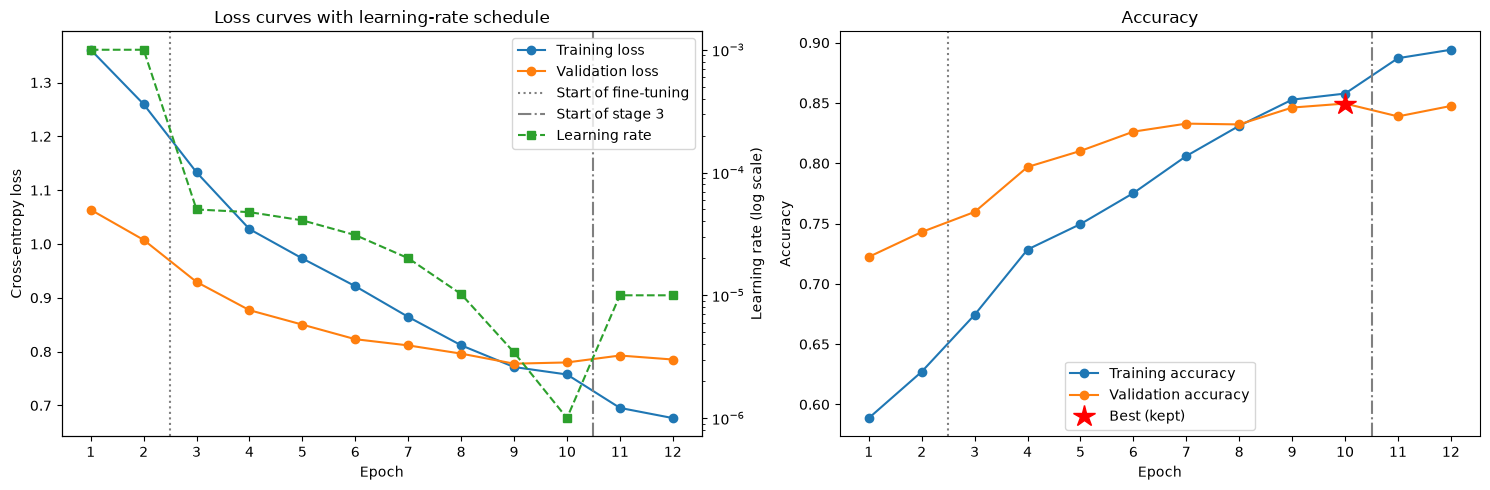

In [17]:
best_row = history.loc[history["val_accuracy"].idxmax()]

fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(15, 5))
ax_loss.plot(history["epoch"], history["loss"], "o-", label="Training loss")
ax_loss.plot(history["epoch"], history["val_loss"], "o-", label="Validation loss")
ax_loss.axvline(HEAD_EPOCHS + 0.5, color="grey", linestyle=":", label="Start of fine-tuning")
ax_loss.axvline(HEAD_EPOCHS + FINE_TUNE_EPOCHS + 0.5, color="grey", linestyle="-.", label="Start of stage 3")
ax_loss.set_xlabel("Epoch")
ax_loss.set_ylabel("Cross-entropy loss")
ax_lr = ax_loss.twinx()
ax_lr.plot(history["epoch"], history["learning_rate"], "s--", color="tab:green", label="Learning rate")
ax_lr.set_yscale("log")
ax_lr.set_ylabel("Learning rate (log scale)")
lines = ax_loss.get_legend_handles_labels()[0] + ax_lr.get_legend_handles_labels()[0]
ax_loss.legend(lines, [l.get_label() for l in lines], loc="upper right")
ax_loss.set_title("Loss curves with learning-rate schedule")

ax_acc.plot(history["epoch"], history["accuracy"], "o-", label="Training accuracy")
ax_acc.plot(history["epoch"], history["val_accuracy"], "o-", label="Validation accuracy")
ax_acc.plot(best_row["epoch"], best_row["val_accuracy"], "*", markersize=16, color="red", label="Best (kept)")
ax_acc.axvline(HEAD_EPOCHS + 0.5, color="grey", linestyle=":")
ax_acc.axvline(HEAD_EPOCHS + FINE_TUNE_EPOCHS + 0.5, color="grey", linestyle="-.")
ax_acc.set_xlabel("Epoch")
ax_acc.set_ylabel("Accuracy")
ax_acc.set_title("Accuracy")
ax_acc.legend()
for ax in (ax_loss, ax_acc):
    ax.set_xticks(history["epoch"])
fig.tight_layout()
save_figure("learning_curves.png")

## 2.12 How Adam uses past gradients (moments)

Plain gradient descent updates each weight with `w = w - lr * g`, using only the current gradient `g`. **Adam**
(Adaptive Moment Estimation) keeps two running averages for every weight:

* **First moment** `m = beta1 * m + (1 - beta1) * g` (beta1 = 0.9): an average of recent gradients, like
  **momentum**. Noise from individual batches cancels out and the update keeps moving in a consistent direction.
* **Second moment** `v = beta2 * v + (1 - beta2) * g^2` (beta2 = 0.999): an average of recent *squared*
  gradients, i.e. how large the gradient of this weight usually is.

Because both start at zero they are bias-corrected (`m_hat = m / (1 - beta1^t)`, `v_hat = v / (1 - beta2^t)`), and the
update is `w = w - lr * m_hat / (sqrt(v_hat) + epsilon)`. Dividing by `sqrt(v_hat)` gives every weight its **own
adaptive step size**: weights with large, noisy gradients take smaller steps, weights with small but consistent
gradients take larger ones. This makes Adam work well with little tuning, which is why it is a common choice for
fine-tuning pre-trained networks. The learning rate `lr` still sets the overall step size, so we also reduce it
during fine-tuning.

## 2.13 Reading the loss curves

The cell below prints the key numbers from the history. How to interpret them:

* **Underfitting** - training *and* validation loss are both still high and falling: the model has not learned enough.
* **Plateau** - a loss stops changing for several epochs (often at the end, when the learning rate is very small).
* **Overfitting** - training loss keeps going down while validation loss reaches its minimum and then rises again;
  training accuracy keeps climbing while validation accuracy stays flat. The epoch with the **lowest validation
  loss** is where overfitting begins.

Note that the training loss is measured *with* augmentation and dropout, while the validation loss is not, so the
training loss can be higher than the validation loss early in training.

In [18]:
min_val_loss_row = history.loc[history["val_loss"].idxmin()]
last = history.iloc[-1]
print(f"Lowest validation loss : {min_val_loss_row['val_loss']:.4f} at epoch {int(min_val_loss_row['epoch'])}")
print(f"Best validation accuracy: {best_row['val_accuracy']:.4f} at epoch {int(best_row['epoch'])}  <- weights kept")
print(f"Last epoch ({int(last['epoch'])}): train acc {last['accuracy']:.4f}, val acc {last['val_accuracy']:.4f}, "
      f"train loss {last['loss']:.4f}, val loss {last['val_loss']:.4f}")
print(f"Train - validation accuracy gap at the end: {last['accuracy'] - last['val_accuracy']:+.4f}")
rising = history[(history["epoch"] > min_val_loss_row["epoch"]) & (history["val_loss"] > min_val_loss_row["val_loss"])]
if len(rising):
    print(f"Validation loss is above its minimum in {len(rising)} later epoch(s) "
          f"-> overfitting starts after epoch {int(min_val_loss_row['epoch'])}.")
else:
    print("Validation loss was still at its lowest in the last epoch -> no clear overfitting yet.")

Lowest validation loss : 0.7776 at epoch 9
Best validation accuracy: 0.8495 at epoch 10  <- weights kept
Last epoch (12): train acc 0.8942, val acc 0.8475, train loss 0.6765, val loss 0.7853
Train - validation accuracy gap at the end: +0.0466
Validation loss is above its minimum in 3 later epoch(s) -> overfitting starts after epoch 9.


## 2.14 Test accuracy and test loss

We load the weights with the best validation accuracy and evaluate them **once** on the HAM10000 test split
(images never used for training or model selection). Because of the image-level split, we also report the
accuracy separately for images of **new lesions** and for images of lesions that also have a photo in the
training set.

In [19]:
model.load_weights(BEST_WEIGHTS)
test_loss, test_accuracy = model.evaluate(test_ds, verbose=0)
print(f"Test images  : {len(test_df):,}")
print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Test loss    : {test_loss:.4f}")

test_probs = model.predict(test_ds, verbose=0)
y_true = test_df["y"].to_numpy()
y_pred = test_probs.argmax(axis=1)
confidence = test_probs.max(axis=1)
print()
print(classification_report(y_true, y_pred, labels=range(NUM_CLASSES), target_names=CLASS_NAMES,
                            digits=3, zero_division=0))

# Data leakage check: accuracy on new lesions vs lesions that also have a photo in the training set
val_pred = model.predict(val_ds, verbose=0).argmax(axis=1)
for name, d, pred in [("Validation", val_df, val_pred), ("Test", test_df, y_pred)]:
    seen = d["lesion_id"].isin(ham_train["lesion_id"]).to_numpy()
    correct = pred == d["y"].to_numpy()
    print(f"{name:10s} all images {correct.mean():.4f} | new lesions {correct[~seen].mean():.4f} "
          f"({(~seen).sum()} images) | lesions also in training {correct[seen].mean():.4f} ({seen.sum()} images)")

Test images  : 1,503
Test accuracy: 0.8583
Test loss    : 0.7562

              precision    recall  f1-score   support

         MEL      0.768     0.455     0.571       167
          NV      0.899     0.966     0.931      1006
         BCC      0.881     0.766     0.819        77
       AKIEC      0.955     0.429     0.592        49
         BKL      0.687     0.824     0.749       165
          DF      0.562     0.529     0.545        17
        VASC      0.850     0.773     0.810        22

    accuracy                          0.858      1503
   macro avg      0.800     0.677     0.717      1503
weighted avg      0.858     0.858     0.849      1503

Validation all images 0.8495 | new lesions 0.8780 (951 images) | lesions also in training 0.8004 (551 images)
Test       all images 0.8583 | new lesions 0.9021 (991 images) | lesions also in training 0.7734 (512 images)


## 2.15 Normalized confusion matrix

Each row is divided by the number of test images of that true class, so the diagonal shows the **recall** of every
class and the off-diagonal cells show which classes are confused with each other.

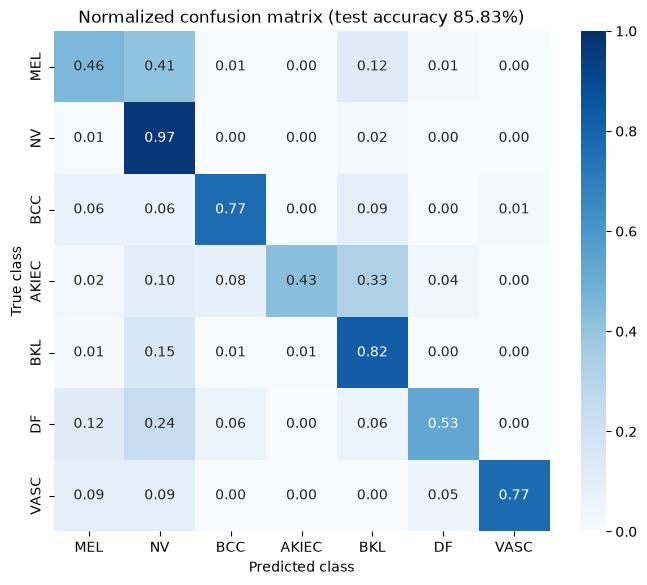

In [20]:
cm = confusion_matrix(y_true, y_pred, labels=range(NUM_CLASSES), normalize="true")
plt.figure(figsize=(8, 6.5))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1,
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.title(f"Normalized confusion matrix (test accuracy {test_accuracy:.2%})")
save_figure("confusion_matrix.png")

## 2.16 Top 3 most confident wrong predictions

Among all wrongly classified test images we pick the three where the model was **most confident** in its wrong
answer. Each image is shown at its original resolution with the true class and the predicted class probability.

       image label predicted  confidence  p_true_class
ISIC_0028758    NV       BKL    0.979926      0.001907
ISIC_0025783   MEL        NV    0.968858      0.013517
ISIC_0029041 AKIEC       BKL    0.941166      0.030762


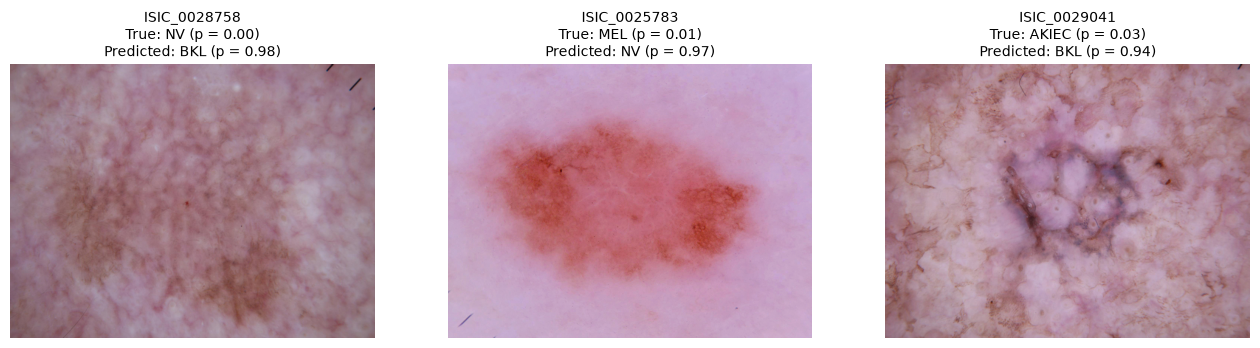

In [21]:
results = test_df[["image", "label", "path"]].copy()
results["predicted"] = [CLASS_NAMES[i] for i in y_pred]
results["confidence"] = confidence
results["p_true_class"] = test_probs[np.arange(len(y_true)), y_true]
top_errors = results[results["label"] != results["predicted"]].nlargest(3, "confidence")
print(top_errors[["image", "label", "predicted", "confidence", "p_true_class"]].to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (_, row) in zip(axes, top_errors.iterrows()):
    ax.imshow(Image.open(row["path"]))
    ax.set_title(f"{row['image']}\nTrue: {row['label']} (p = {row['p_true_class']:.2f})\n"
                 f"Predicted: {row['predicted']} (p = {row['confidence']:.2f})", fontsize=10)
for ax in axes:
    ax.axis("off")
save_figure("top3_confident_errors.png")

## 2.17 Error analysis

Look at the three images above together with the confusion matrix. Typical reasons for confident mistakes on this
dataset are:

* **Visual overlap between classes.** Melanoma (MEL), benign nevi (NV) and benign keratoses (BKL) can all be brown,
  roughly round lesions with a pigment network. Early melanomas often look like ordinary moles, which is why
  MEL <-> NV and MEL <-> BKL are the most common confusions, even for dermatologists.
* **Class imbalance.** About half of the training images are NV. When the evidence is unclear, the network has
  learned that "NV" is the safest guess, so errors towards NV come with high confidence.
* **Background noise and artefacts.** Hairs, air bubbles, ruler marks, ink and the dark circular vignette of the
  dermoscope cover parts of the lesion and can hide or imitate the patterns the model relies on.
* **Lighting and colour variation.** Different cameras and lighting conditions change the colour and contrast of the
  same kind of lesion.
* **Resolution.** Even at 384 x 384, resizing removes some fine details of small lesions (e.g. irregular dots or
  streaks at the border) that can separate a melanoma from a nevus.

These are explanations based on what is visible in the images; they are not a proof of what the network looked at.

## 2.18 Class probabilities for an unseen test image

We pick one random image from the test split (never used for training or model selection), predict its class
probabilities from the image and its metadata, and show them as a horizontal bar chart.

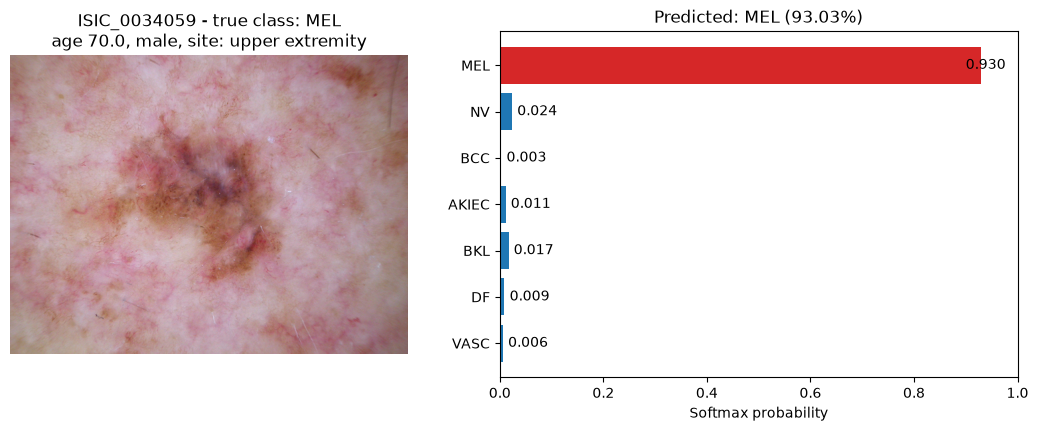

In [22]:
rng = np.random.default_rng(SEED)
unseen_index = int(rng.integers(len(test_df)))
unseen = test_df.iloc[unseen_index]
unseen_image, _ = load_image(unseen["file"], unseen["y"])
unseen_inputs = {"image": unseen_image[None], "metadata": metadata_matrix(test_df.iloc[[unseen_index]])}
unseen_probs = model.predict(unseen_inputs, verbose=0)[0]

fig, (ax_img, ax_bar) = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [1, 1.3]})
ax_img.imshow(Image.open(unseen["path"]))
ax_img.set_title(f"{unseen['image']} - true class: {unseen['label']}\n"
                 f"age {unseen['age']}, {unseen['sex']}, site: {unseen['site']}")
ax_img.axis("off")
colours = ["tab:red" if name == CLASS_NAMES[unseen_probs.argmax()] else "tab:blue" for name in CLASS_NAMES]
ax_bar.barh(CLASS_NAMES, unseen_probs, color=colours)
ax_bar.invert_yaxis()
ax_bar.set_xlim(0, 1)
ax_bar.set_xlabel("Softmax probability")
ax_bar.set_title(f"Predicted: {CLASS_NAMES[unseen_probs.argmax()]} ({unseen_probs.max():.2%})")
for i, p in enumerate(unseen_probs):
    ax_bar.text(min(p + 0.01, 0.9), i, f"{p:.3f}", va="center")
save_figure("unseen_image_prediction.png")

## 2.19 From logits to probabilities with Softmax

The last dense layer outputs one raw score per class, the **logits** `z_1 ... z_7`. They can be any real numbers.
Softmax turns them into probabilities:

$$p_k = \frac{e^{z_k}}{\sum_{j=1}^{7} e^{z_j}}$$

The exponential makes every value positive and keeps the order of the scores (a larger logit gives a larger
probability); dividing by the sum makes the seven probabilities add up to 1. Differences between logits become
ratios between probabilities: if `z_a - z_b = 2`, class `a` is `e^2 ≈ 7.4` times more likely than class `b`. In
practice the maximum logit is subtracted first (`z_k - max z`); this gives the same result and avoids overflow. The
cell below reads the logits of the unseen image from the `logits` layer and applies the formula by hand.

In [23]:
logit_model = keras.Model(model.input, model.get_layer("logits").output)
z = logit_model.predict(unseen_inputs, verbose=0)[0]
manual_softmax = np.exp(z - z.max()) / np.exp(z - z.max()).sum()

print(pd.DataFrame({"logit z": z, "exp(z - max z)": np.exp(z - z.max()),
                    "softmax by hand": manual_softmax, "model output": unseen_probs},
                   index=CLASS_NAMES).round(4))
print("Sum of probabilities:", manual_softmax.sum().round(6))
print("Hand-made softmax matches the model:", np.allclose(manual_softmax, unseen_probs, atol=1e-5))

       logit z  exp(z - max z)  softmax by hand  model output
MEL     2.9237          1.0000           0.9303        0.9303
NV     -0.7484          0.0254           0.0236        0.0236
BCC    -2.8374          0.0031           0.0029        0.0029
AKIEC  -1.4931          0.0121           0.0112        0.0112
BKL    -1.0861          0.0181           0.0169        0.0169
DF     -1.7114          0.0097           0.0090        0.0090
VASC   -2.1206          0.0064           0.0060        0.0060
Sum of probabilities: 1.0
Hand-made softmax matches the model: True


## 2.20 Overconfidence and calibration

A model is **well calibrated** if its confidence matches how often it is right: among all predictions made with
about 80 % confidence, about 80 % should be correct. Deep networks are often **overconfident**:

* Cross-entropy keeps rewarding the model for pushing the correct logit even higher, so after many epochs the logits
  become very large and softmax outputs probabilities close to 1, even on hard images.
* Softmax always has to spread 100 % over the seven known classes; it has no way to say "I don't know", so an
  unusual image (artefacts, rare appearance) can still get a very high probability for a wrong class.
* Training images and new images differ (different hospitals, cameras, lighting), but the model's confidence does
  not take this into account.

The reliability diagram below groups the test predictions into 10 confidence bins and compares the average
confidence with the actual accuracy in each bin. Bars below the diagonal mean overconfidence. The **Expected
Calibration Error (ECE)** is the weighted average gap between the two. Common fixes are temperature scaling (dividing
the logits by a constant fitted on the validation set), label smoothing, and ensembles.

    bin  count  mean confidence  accuracy
0.2-0.3      4            0.268     0.250
0.3-0.4     32            0.363     0.344
0.4-0.5     71            0.457     0.451
0.5-0.6     98            0.554     0.531
0.6-0.7    102            0.646     0.706
0.7-0.8    159            0.754     0.780
0.8-0.9    380            0.862     0.924
0.9-1.0    657            0.931     0.985

Mean confidence: 0.8148 | accuracy: 0.8583 | ECE: 0.0481
Wrong predictions with confidence above 0.9: 10


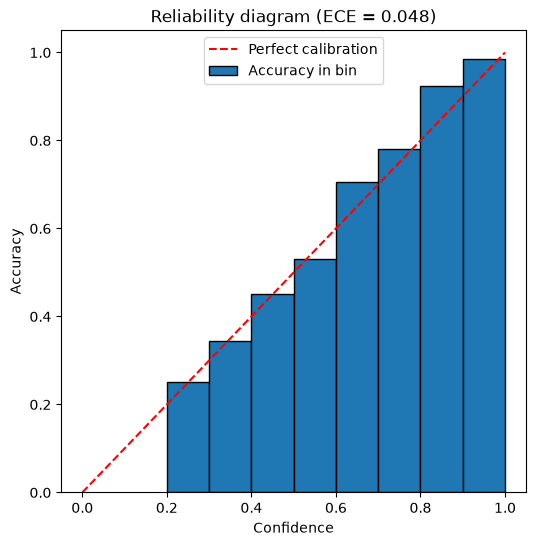

In [24]:
bins = np.linspace(0, 1, 11)
bin_index = np.clip(np.digitize(confidence, bins) - 1, 0, 9)
correct = (y_pred == y_true)
rows = []
for b in range(10):
    in_bin = bin_index == b
    if in_bin.any():
        rows.append({"bin": f"{bins[b]:.1f}-{bins[b + 1]:.1f}", "count": int(in_bin.sum()),
                     "mean confidence": confidence[in_bin].mean(), "accuracy": correct[in_bin].mean()})
calibration = pd.DataFrame(rows)
ece = (calibration["count"] / len(y_true) * (calibration["accuracy"] - calibration["mean confidence"]).abs()).sum()
print(calibration.round(3).to_string(index=False))
print(f"\nMean confidence: {confidence.mean():.4f} | accuracy: {correct.mean():.4f} | ECE: {ece:.4f}")
print(f"Wrong predictions with confidence above 0.9: {int(((~correct) & (confidence > 0.9)).sum())}")

plt.figure(figsize=(6, 6))
centres = (bins[:-1] + bins[1:]) / 2
acc_per_bin = np.full(10, np.nan)
for b in range(10):
    if (bin_index == b).any():
        acc_per_bin[b] = correct[bin_index == b].mean()
plt.bar(centres, acc_per_bin, width=0.1, edgecolor="black", label="Accuracy in bin")
plt.plot([0, 1], [0, 1], "--", color="red", label="Perfect calibration")
plt.xlabel("Confidence")
plt.ylabel("Accuracy")
plt.title(f"Reliability diagram (ECE = {ece:.3f})")
plt.legend()
save_figure("reliability_diagram.png")

## Saving the results

The test predictions and a short summary are saved to `outputs/` for the report.

In [25]:
results.drop(columns="path").to_csv(RUN_DIR / "test_predictions.csv", index=False)
summary = pd.Series(dtype=object, data={
    "training images": len(train_df), "validation images": len(val_df), "test images": len(test_df),
    "epochs": TOTAL_EPOCHS, "best epoch": int(best_row["epoch"]),
    "best validation accuracy": round(float(best_row["val_accuracy"]), 4),
    "test accuracy": round(float(test_accuracy), 4), "test loss": round(float(test_loss), 4),
    "ECE": round(float(ece), 4),
})
summary.to_csv(RUN_DIR / "summary.csv", header=["value"])
print(summary.to_string())
print("\nFiles saved in", RUN_DIR)

training images              27921
validation images             1502
test images                   1503
epochs                          12
best epoch                      10
best validation accuracy    0.8495
test accuracy               0.8583
test loss                   0.7562
ECE                         0.0481

Files saved in /Users/hill/dev/DL Group Assignment/outputs/run_384px_image_split_meta
